# Projet Triple A – UOI Games : analyses du marché du jeu vidéo

**Livrable 2 – Analyses** · Ratiba Benzerouali · Data ESN · novembre 2026

Ce notebook contient toutes les analyses chiffrées utilisées dans la présentation. Chaque chiffre de la présentation provient soit d'une cellule de ce notebook, soit d'une source externe citée dans la section 9.

**Plan**
1. Chargement et nettoyage des 3 fichiers fournis
2. Tendances historiques des ventes (1980-2016)
3. Offre et notes des joueurs (base de jeux 2000-2020)
4. Test de corrélation : note Metacritic et ventes
5. Parc de consoles (fichier fourni + mise à jour 2026)
6. Marché actuel : données externes (Newzoo, SELL)
7. Questionnaire joueurs : profil, préférences et corrélations
8. Prévision grossière des ventes (3 scénarios)
9. Sources

**Comment lire ce notebook**

| Section | Question | Diapositive | Type |
|---|---|---|---|
| 1 | Les données sont-elles propres ? | aucune | préparation |
| 2 | Quel genre se vend le plus ? | 8, 19, 25 | calcul (fichiers fournis) |
| 3 | Quel genre est le plus concurrentiel ? | 9 | calcul (fichiers fournis) |
| 4 | La qualité fait-elle vendre ? | 10 | calcul (fichiers fournis) |
| 5 | Combien de consoles ? | 14 | chiffres en ligne recopiés |
| 6 | Quelle taille de marché ? | 7, 8 | chiffres en ligne recopiés |
| 7 | Que veulent les joueurs ? | 17, 18, 24 | calcul (questionnaire) |
| 8 | Combien de ventes ? | 25 | calcul + repères en ligne |
| 9 | Sources | annexe | liste |

**Choix méthodologiques**
- Les ventes de jeux sont très asymétriques (quelques énormes succès, une longue traîne). Les corrélations sont donc testées avec **Spearman** (corrélation de rang), qui ne suppose pas de distribution normale. Seuil de significativité : 5 %.
- Les données externes (non présentes dans les fichiers) sont saisies dans des tableaux avec une colonne `source`.

In [1]:
import pandas as pd, numpy as np, re, warnings
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)

DATA = 'data/'
CH = 'charts/'
# Palette reprise du template UOI Games
VIOLET, VIOLET2, LILAS, PALE, CYAN, GRIS = '#351C75', '#674EA7', '#A288E2', '#C1B6DC', '#0097A7', '#9E9E9E'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.titlesize': 13})
def save(fig, name):
    fig.tight_layout(); fig.savefig(CH + name, dpi=200, bbox_inches='tight', facecolor='white'); plt.show()

## 1. Chargement et nettoyage des fichiers fournis

➜ **Préparation des données** : aucun chiffre de la présentation ici, on vérifie et on nettoie les fichiers avant de calculer.

### 1.1 Ventes de jeux de plus de 100 000 exemplaires (1980-2016)

In [2]:
vg_raw = pd.read_excel(DATA + 'VideoGame_Sales_1980-2016__1_.xlsb', sheet_name='vgsales', engine='pyxlsb')
vg_raw.columns = [c.strip() for c in vg_raw.columns]
print('Dimensions brutes :', vg_raw.shape)
print('Doublons exacts :', vg_raw.duplicated().sum())
print('Valeurs manquantes :'); print(vg_raw.isna().sum()[vg_raw.isna().sum() > 0])
print('Répartition des années récentes :'); print(vg_raw['Year'].value_counts().sort_index().tail(6))

Dimensions brutes : (16545, 13)
Doublons exacts : 0
Valeurs manquantes :
Year         271
Publisher     58
dtype: int64
Répartition des années récentes :
Year
2013.0    543
2014.0    578
2015.0    608
2016.0    344
2017.0      3
2020.0      1
Name: count, dtype: int64


**Constats et décisions de nettoyage**
- Les années 2017 à 2020 ne comptent que quelques jeux (données incomplètes) : on garde **1980-2016**.
- Les lignes sans année sont exclues des analyses temporelles.
- 2016 est aussi une année partielle (le fichier s'arrête en cours d'année) : elle est conservée pour les cumuls mais signalée.
- Les ventes sont en **millions d'unités**. Une ligne = un jeu sur une plateforme.

In [3]:
vg = vg_raw[vg_raw['Year'].notna() & (vg_raw['Year'] <= 2016)].copy()
vg['Year'] = vg['Year'].astype(int)
print('Lignes conservées :', len(vg), '| lignes exclues :', len(vg_raw) - len(vg))
vg.head()

Lignes conservées : 16270 | lignes exclues : 275


,Rank,Name,Platform,Year,Genre,Publisher,Constructeur,Portable,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,Nintendo,Non,41.4900,27.8592,3.6569,8.2908,81.2969
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,Nintendo,Non,29.9524,3.4726,6.6738,0.8085,40.9073
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,Nintendo,Non,15.2160,12.4936,3.7900,3.3762,34.8758
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,Nintendo,Non,15.7500,11.0100,3.1816,3.0784,33.0200
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,Nintendo,Oui,11.2700,9.0678,9.8112,0.9900,31.1390


### 1.2 Base de tous les jeux avec notes des joueurs (2000-2020)

In [4]:
cols = ['name', 'metacritic', 'Annee', 'rating', 'ratings_count', 'genres', 'PC', 'PlayStation 4',
        'Xbox One', 'Nintendo Switch', 'PlayStation 5', 'Xbox Series S/X']
rawg = pd.read_excel(DATA + 'All_publish_VideoGame_2022.xlsb', engine='pyxlsb', usecols=cols)
print('Dimensions :', rawg.shape)
print('Jeux avec note Metacritic :', rawg['metacritic'].notna().sum())
print('Jeux avec au moins 50 notes joueurs :', (rawg['ratings_count'] >= 50).sum())
print(rawg['Annee'].value_counts().sort_index().tail(7))

Dimensions : (440896, 12)
Jeux avec note Metacritic : 4627
Jeux avec au moins 50 notes joueurs : 2904
Annee
2014     15439
2015     26225
2016     41065
2017     56173
2018     71152
2019     79134
2020    118450
Name: count, dtype: int64


**Constats** : 440 896 jeux, mais les notes sont très clairsemées. Pour que les moyennes aient un sens, les analyses de notes ne retiennent que les jeux ayant **au moins 50 notes de joueurs**. Les genres sont stockés en texte séparé par `||` : un jeu peut appartenir à plusieurs genres (on éclate la colonne).

In [5]:
rawg_g = rawg.assign(genre=rawg['genres'].fillna('').str.split(r'\|\|')).explode('genre')
rawg_g = rawg_g[rawg_g['genre'] != '']

### 1.3 Ventes de consoles (2022)

In [6]:
cons = pd.read_excel(DATA + 'Vente_de_console_2022.xlsx')
cons

,Console,Constructeur,Date de Sortie,Vente (en million)
0,PlayStation 2,Sony,2000,158.0000
1,Nintendo DS,Nintendo,2004,157.1004
2,Switch,Nintendo,2017,126.8762
3,Game Boy (avec Color),Nintendo,1989,118.6900
4,PlayStation 4,Sony,2013,115.8300
5,PlayStation,Sony,1994,103.4240
6,Wii,Nintendo,2006,99.5974
7,PlayStation 3,Sony,2006,87.9040
8,Xbox 360,Microsoft,2005,83.2000
9,PSP,Sony,2004,81.9750


Le fichier ne contient ni la Xbox Series, ni la Switch 2 (sortie en 2025). Il est mis à jour en section 5 avec les chiffres publiés par les constructeurs.

## 2. Tendances historiques des ventes (1980-2016)

### 2.1 Part de chaque genre dans les ventes mondiales, par période

➜ **Utilisé dans la présentation : diapositive 8** (29,8 % contre 18,5 %). Type : calcul sur le fichier des ventes. Formule : ventes des jeux d'action ÷ ventes de tous les jeux.

In [7]:
vg['periode'] = pd.cut(vg['Year'], [1979, 1999, 2009, 2016], labels=['1980-1999', '2000-2009', '2010-2016'])
part = vg.pivot_table(index='Genre', columns='periode', values='Global_Sales', aggfunc='sum', observed=True)
part = (part / part.sum() * 100).round(1).sort_values('2010-2016', ascending=False)
part

periode,1980-1999,2000-2009,2010-2016
Genre,,,
Action,11.5,18.5,29.8
Shooter,7.8,9.4,17.6
Sports,10.9,17.3,12.3
Role-Playing,12.1,9.0,11.6
Misc,4.3,10.5,9.1
Racing,9.8,9.5,4.7
Platform,19.9,8.1,4.6
Fighting,7.8,5.0,3.1
Simulation,3.2,5.7,2.7


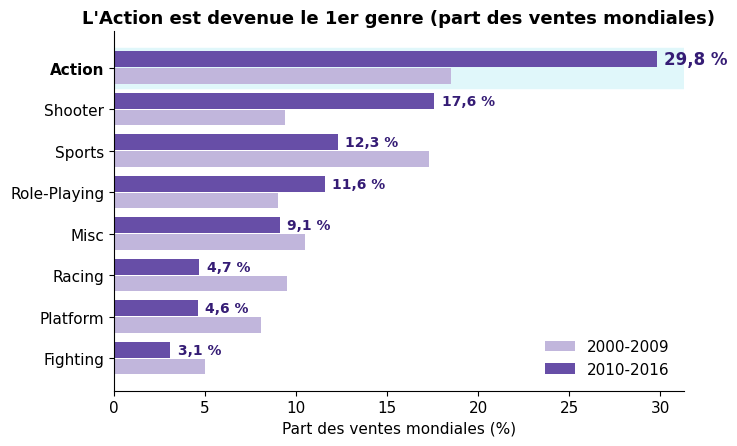

In [8]:
top = part.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
y = np.arange(len(top))
ax.barh(y - 0.2, top['2000-2009'], height=0.38, color=PALE, label='2000-2009')
i_act = list(top.index).index('Action')
ax.axhspan(i_act - 0.48, i_act + 0.48, color='#E0F7FA', zorder=0)
ax.barh(y + 0.2, top['2010-2016'], height=0.38, color=VIOLET2, label='2010-2016')
for i, val in enumerate(top['2010-2016']):
    act = (top.index[i] == 'Action')
    ax.text(val + 0.4, i + 0.2, f'{val:.1f} %'.replace('.', ','), va='center', fontsize=12 if act else 10, color=VIOLET, fontweight='bold')
ax.set_yticks(y); ax.set_yticklabels(top.index)
for lab in ax.get_yticklabels():
    if lab.get_text() == 'Action':
        lab.set_fontweight('bold')
ax.set_xlabel('Part des ventes mondiales (%)')
ax.set_title("L'Action est devenue le 1er genre (part des ventes mondiales)")
ax.legend(frameon=False, loc='lower right')
save(fig, 'ch_genres_periodes.png')

**Lecture** : sur 2010-2016, l'**Action** représente près de 30 % des ventes mondiales, contre 18,5 % sur 2000-2009. Le Shooter (17,6 %) et le RPG (11,6 %) suivent. C'est la principale tendance de fond du fichier.

### 2.2 Genres par zone géographique (2010-2016)

➜ **Utilisé dans la présentation : diapositive 19** (choix des zones Europe et Amérique du Nord). Type : calcul sur le fichier des ventes.

In [9]:
r = vg[vg['Year'] >= 2010]
zones = r.groupby('Genre')[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']].sum()
zones_pct = (zones / zones.sum() * 100).round(1).sort_values('EU_Sales', ascending=False)
zones_pct.head(8)

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
Genre,,,,
Action,28.6,32.0,24.3,33.1
Shooter,19.8,18.8,4.5,19.2
Sports,13.3,13.1,5.1,13.8
Role-Playing,9.3,8.3,33.5,8.3
Misc,10.9,7.7,8.0,7.3
Racing,3.9,6.2,2.2,5.6
Platform,4.8,4.4,5.2,3.8
Simulation,2.3,2.9,4.4,2.1


**Lecture** : l'Action est le 1er genre en Amérique du Nord (28,6 %) et en Europe (32,0 %). Le Japon se distingue avec le **RPG en tête (33,5 %)** et un faible poids du Shooter (4,5 %). Un jeu d'action avec éléments de RPG parle donc aux trois grandes zones.

### 2.3 Combien vend un jeu d'action récent ?

➜ **Utilisé dans la présentation : diapositive 25 (prévision, scénarios prudent et central).** Type : calcul sur le fichier fourni.

In [10]:
gen8 = vg[(vg['Year'] >= 2013) & (vg['Platform'].isin(['PS4', 'XOne', 'PC']))]
titres = gen8.groupby(['Name', 'Genre'], as_index=False)['Global_Sales'].sum()
action = titres[titres['Genre'] == 'Action']['Global_Sales']
quantiles = action.quantile([0.5, 0.75, 0.9, 0.95]).round(2)
print('Jeux Action sortis 2013-2016 sur PS4 / Xbox One / PC :', len(action))
print('Ventes cumulées (millions) par quantile :'); print(quantiles)
titres[titres['Genre'] == 'Action'].sort_values('Global_Sales', ascending=False).head(10)

Jeux Action sortis 2013-2016 sur PS4 / Xbox One / PC : 143
Ventes cumulées (millions) par quantile :
0.50    0.16
0.75    0.78
0.90    2.70
0.95    4.54
Name: Global_Sales, dtype: float64


,Name,Genre,Global_Sales
152,Grand Theft Auto V,Action,57.4998
21,Assassin's Creed: Unity,Action,7.8696
419,Watch Dogs,Action,6.2541
18,Assassin's Creed IV: Black Flag,Action,5.6274
28,Batman: Arkham Knight,Action,5.4379
19,Assassin's Creed Syndicate,Action,4.7860
213,Middle-Earth: Shadow of Mordor,Action,4.6719
365,The Last of Us,Action,4.5419
407,Uncharted: The Nathan Drake Collection,Action,4.5180
211,Metal Gear Solid V: The Phantom Pain,Action,4.2655


**Lecture** : la moitié des jeux d'action de cette génération vendent moins de 0,16 M d'unités (dans ce fichier), mais le **top 10 % dépasse 2,7 M**. Deux **nouvelles licences** figurent parmi les meilleures ventes du genre : *Watch Dogs* (≈ 6,3 M) et *Middle-earth: Shadow of Mordor* (≈ 4,7 M). Ces repères servent à la prévision (section 8).

*Limite* : ces chiffres s'arrêtent en 2016 et ne couvrent qu'une partie des ventes dématérialisées ; ce sont des ordres de grandeur.

## 3. Combien de jeux sortent dans chaque genre ?

➜ **Utilisé dans la présentation : diapositive 9.** Type : calcul (comptage) sur le fichier des 440 896 jeux.

In [11]:
offre = rawg_g[rawg_g['Annee'].between(2016, 2020)]['genre'].value_counts().head(10)
print('Nombre de jeux publiés par genre (2016-2020) :'); print(offre)

Nombre de jeux publiés par genre (2016-2020) :
genre
Action        76177
Adventure     56183
Platformer    44078
Puzzle        43943
Simulation    30317
Shooter       26806
Indie         22595
RPG           21868
Strategy      21467
Casual        19337
Name: count, dtype: int64


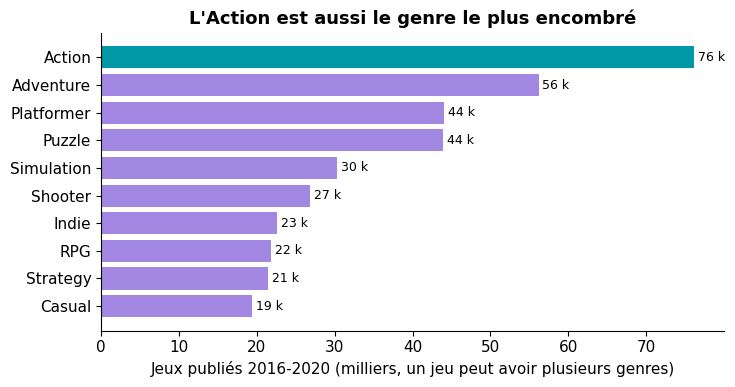

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4))
o = offre.iloc[::-1]
ax.barh(o.index, o.values / 1000, color=[CYAN if g == 'Action' else LILAS for g in o.index])
for i, val in enumerate(o.values):
    ax.text(val / 1000 + 0.5, i, f'{val/1000:.0f} k', va='center', fontsize=9)
ax.set_xlabel('Jeux publiés 2016-2020 (milliers, un jeu peut avoir plusieurs genres)')
ax.set_title("L'Action est aussi le genre le plus encombré")
save(fig, 'ch_offre_genres.png')

**Lecture** : l'Action est le genre où il sort le plus de jeux (76 177 entre 2016 et 2020) : la concurrence y est la plus forte. Conséquence : dans un genre encombré, il faut se différencier. La section 4 vérifie si la qualité fait la différence.

## 4. Test de corrélation : la note Metacritic est-elle liée aux ventes ?

➜ **Utilisé dans la présentation : diapositive 10** (ρ = 0,35, 11 fois plus de ventes). Type : calcul croisant les deux fichiers fournis. C'est l'analyse la plus importante du projet.

**Hypothèse H1** : les jeux les mieux notés par la critique vendent davantage.

**Méthode** : rapprochement des deux fichiers par le nom du jeu (nom normalisé : minuscules, sans ponctuation), sur 2000-2016. Ventes cumulées toutes plateformes. Test de Spearman.

In [13]:
norm = lambda s: re.sub(r'[^a-z0-9]', '', str(s).lower())
ventes_titre = (vg[vg['Year'].between(2000, 2016)].groupby('Name')
                .agg(ventes=('Global_Sales', 'sum'), genre=('Genre', 'first')).reset_index())
ventes_titre['cle'] = ventes_titre['Name'].map(norm)
meta = rawg[rawg['metacritic'].notna() & rawg['Annee'].between(2000, 2016)].copy()
meta['cle'] = meta['name'].map(norm)
meta = meta.sort_values('ratings_count', ascending=False).drop_duplicates('cle')
jointure = ventes_titre.merge(meta[['cle', 'metacritic']], on='cle')
print('Jeux rapprochés :', len(jointure))

rho, p = spearmanr(jointure['metacritic'], jointure['ventes'])
print(f'Tous genres : rho = {rho:.2f}, p = {p:.1e}')
res = []
for g in ['Action', 'Role-Playing', 'Shooter', 'Adventure', 'Sports']:
    s = jointure[jointure['genre'] == g]
    r_, p_ = spearmanr(s['metacritic'], s['ventes'])
    res.append((g, len(s), round(r_, 2), f'{p_:.1e}'))
pd.DataFrame(res, columns=['Genre', 'n', 'rho', 'p-value'])

Jeux rapprochés : 1266
Tous genres : rho = 0.35, p = 1.2e-38


,Genre,n,rho,p-value
0,Action,299,0.44,1.3e-15
1,Role-Playing,182,0.49,2.0e-12
2,Shooter,217,0.43,2.7e-11
3,Adventure,72,0.39,7.6e-04
4,Sports,68,0.36,2.3e-03


         count  median
classe                
< 70       339    0.36
70-79      398    0.64
80-89      423    1.41
90 et +    106    4.12
Un jeu noté 90 et + vend 11.4 fois plus (médiane) qu'un jeu noté moins de 70 : 4.12 ÷ 0.36


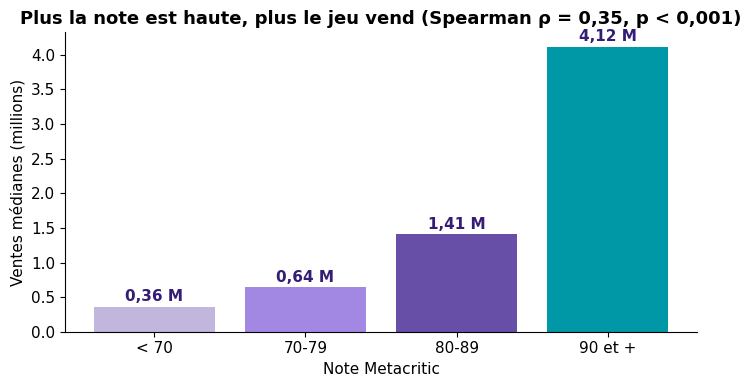

In [14]:
jointure['classe'] = pd.cut(jointure['metacritic'], [0, 69, 79, 89, 100], labels=['< 70', '70-79', '80-89', '90 et +'])
par_classe = jointure.groupby('classe', observed=True)['ventes'].agg(['count', 'median']).round(2)
print(par_classe)
ratio = par_classe.loc['90 et +', 'median'] / par_classe.loc['< 70', 'median']
print(f"Un jeu noté 90 et + vend {ratio:.1f} fois plus (médiane) qu'un jeu noté moins de 70 : "
      f"{par_classe.loc['90 et +', 'median']} ÷ {par_classe.loc['< 70', 'median']}")
fig, ax = plt.subplots(figsize=(7.2, 4))
ax.bar(par_classe.index.astype(str), par_classe['median'], color=[PALE, LILAS, VIOLET2, CYAN])
for i, val in enumerate(par_classe['median']):
    ax.text(i, val + 0.08, f'{val:.2f} M'.replace('.', ','), ha='center', fontsize=11, fontweight='bold', color=VIOLET)
ax.set_xlabel('Note Metacritic'); ax.set_ylabel('Ventes médianes (millions)')
ax.set_title(f'Plus la note est haute, plus le jeu vend (Spearman ρ = {rho:.2f}, p < 0,001)'.replace('0.', '0,'))
save(fig, 'ch_metacritic_ventes.png')

**Conclusion H1 : confirmée.** La corrélation est positive et significative (ρ ≈ 0,35 tous genres, p < 0,001), et plus forte pour l'**Action (ρ ≈ 0,44)** et le **RPG (ρ ≈ 0,49)**. Un jeu noté 90 et plus vend en médiane environ 11 fois plus qu'un jeu noté moins de 70 (4,12 M ÷ 0,36 M, calcul affiché ci-dessus).

*Limites* : corrélation ne veut pas dire causalité (un gros budget peut améliorer à la fois la note et le marketing) ; le rapprochement par nom ne retrouve qu'une partie des jeux (1 266).

## 5. Parc de consoles : fichier fourni + mise à jour 2026

➜ **Utilisé dans la présentation : diapositive 14.** Type : chiffres trouvés en ligne (Sony, Nintendo, VGChartz), simplement recopiés ici pour dessiner le graphique. Aucun calcul, sauf l'addition PS5 + Xbox ≈ 130 M.

In [15]:
parc = pd.DataFrame([
    ['PlayStation 5', 95.3, '30/06/2026', 'Sony, résultats T1 exercice 2026 (via Thurrott)', 'officiel'],
    ['Nintendo Switch', 156.59, '30/06/2026', 'Nintendo, résultats T1 exercice 2027 (via Nintendo Life)', 'officiel'],
    ['Xbox Series X|S', 34.17, '31/12/2025', 'VGChartz (estimation, Microsoft ne publie pas ses ventes)', 'estimation'],
    ['Nintendo Switch 2', 23.68, '30/06/2026', 'Nintendo, résultats T1 exercice 2027 (via Nintendo Life)', 'officiel'],
], columns=['console', 'millions', 'date', 'source', 'statut'])
parc

,console,millions,date,source,statut
0,PlayStation 5,95.30,30/06/2026,"Sony, résultats T1 exercice 2026 (via Thurrott)",officiel
1,Nintendo Switch,156.59,30/06/2026,"Nintendo, résultats T1 exercice 2027 (via Nint...",officiel
2,Xbox Series X|S,34.17,31/12/2025,"VGChartz (estimation, Microsoft ne publie pas ...",estimation
3,Nintendo Switch 2,23.68,30/06/2026,"Nintendo, résultats T1 exercice 2027 (via Nint...",officiel


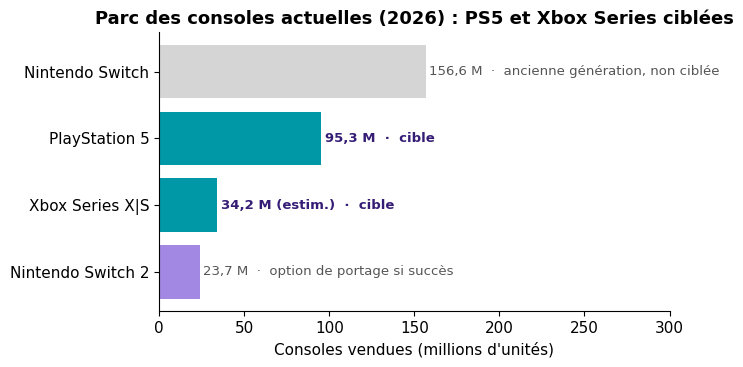

In [16]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
p = parc.sort_values('millions')
statut_cible = {'PlayStation 5': ('cible', CYAN), 'Xbox Series X|S': ('cible', CYAN),
                'Nintendo Switch 2': ('option de portage si succès', LILAS),
                'Nintendo Switch': ('ancienne génération, non ciblée', '#D5D5D5')}
cols_ = [statut_cible[c][1] for c in p['console']]
ax.barh(p['console'], p['millions'], color=cols_)
for i, (c_, val, st) in enumerate(zip(p['console'], p['millions'], p['statut'])):
    lab = f'{val:.1f} M'.replace('.', ',') + (' (estim.)' if st == 'estimation' else '')
    ax.text(val + 2, i, lab + '  ·  ' + statut_cible[c_][0], va='center', fontsize=9.5,
            color=VIOLET if statut_cible[c_][0] == 'cible' else '#555555',
            fontweight='bold' if statut_cible[c_][0] == 'cible' else 'normal')
ax.set_xlabel("Consoles vendues (millions d'unités)")
ax.set_title('Parc des consoles actuelles (2026) : PS5 et Xbox Series ciblées')
ax.set_xlim(0, 300)
save(fig, 'ch_parc_consoles.png')

**Lecture** : en juin 2026, le parc PS5 (95,3 M) et Xbox Series (≈ 34 M, estimation) représente environ **130 M de consoles**, la cible du jeu. La Switch 1 (156,6 M) est la plus vendue, mais c'est une console de 2017, remplacée par la Switch 2 : elle n'est pas ciblée. La Switch 2 (23,7 M) est gardée comme option de portage en cas de succès.

**PC** : il n'existe pas de « parc de PC de jeu » publié. Repère disponible : Steam, la principale boutique de jeux PC, a compté **43,5 M d'utilisateurs connectés en même temps** le 11 octobre 2026 (record ; SteamDB, via Kotaku et KitGuru). Ce chiffre n'est pas comparable à un nombre de consoles vendues : c'est un minimum de joueurs PC actifs au même moment.

## 6. Marché actuel : données externes

➜ **Utilisé dans la présentation : diapositives 7 et 8.** Type : chiffres trouvés en ligne (Newzoo, SELL), simplement recopiés ici pour dessiner les graphiques. Aucun calcul.

In [17]:
marche = pd.DataFrame([
    ['Mobile', 113.3, 10.7], ['Console', 44.7, 2.8], ['PC', 43.6, 12.0]],
    columns=['segment', 'CA_2025_Md$', 'croissance_%'])
marche['source'] = 'Newzoo, Global Games Market Report 2025 (via Pocketgamer.biz, GameDev.net)'
print('Total 2025 : 201,6 Md$ (+9,1 %) · Prévision 2028 : 234,4 Md$ (TCAC 5,1 %)')
marche

Total 2025 : 201,6 Md$ (+9,1 %) · Prévision 2028 : 234,4 Md$ (TCAC 5,1 %)


,segment,CA_2025_Md$,croissance_%,source
0,Mobile,113.3,10.7,"Newzoo, Global Games Market Report 2025 (via P..."
1,Console,44.7,2.8,"Newzoo, Global Games Market Report 2025 (via P..."
2,PC,43.6,12.0,"Newzoo, Global Games Market Report 2025 (via P..."


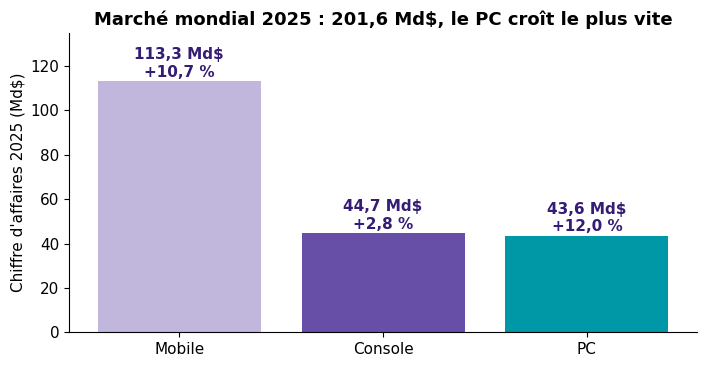

In [18]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.bar(marche['segment'], marche['CA_2025_Md$'], color=[PALE, VIOLET2, CYAN])
for i, (val, g) in enumerate(zip(marche['CA_2025_Md$'], marche['croissance_%'])):
    ax.text(i, val + 2, f'{val:.1f} Md$\n+{g:.1f} %'.replace('.', ','), ha='center', fontsize=11, fontweight='bold', color=VIOLET)
ax.set_ylabel("Chiffre d'affaires 2025 (Md$)"); ax.set_ylim(0, 135)
ax.set_title('Marché mondial 2025 : 201,6 Md$, le PC croît le plus vite')
save(fig, 'ch_marche_2025.png')

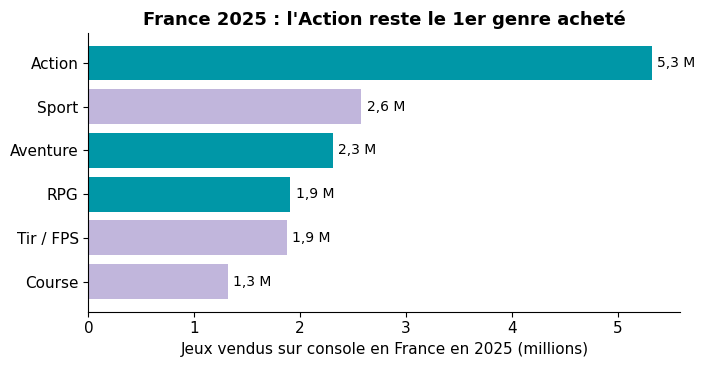

,genre,unites_console_2025,source
0,Action,5327023,"SELL, L'Essentiel du jeu vidéo, avril 2026 (pa..."
1,Sport,2578859,"SELL, L'Essentiel du jeu vidéo, avril 2026 (pa..."
2,Aventure,2311489,"SELL, L'Essentiel du jeu vidéo, avril 2026 (pa..."
3,RPG,1908325,"SELL, L'Essentiel du jeu vidéo, avril 2026 (pa..."
4,Tir / FPS,1873259,"SELL, L'Essentiel du jeu vidéo, avril 2026 (pa..."
5,Course,1316546,"SELL, L'Essentiel du jeu vidéo, avril 2026 (pa..."


In [19]:
fr_genres = pd.DataFrame([
    ['Action', 5327023], ['Sport', 2578859], ['Aventure', 2311489], ['RPG', 1908325],
    ['Tir / FPS', 1873259], ['Course', 1316546]], columns=['genre', 'unites_console_2025'])
fr_genres['source'] = "SELL, L'Essentiel du jeu vidéo, avril 2026 (panel GSD, console, physique + dématérialisé)"
fig, ax = plt.subplots(figsize=(7.2, 3.8))
f = fr_genres.iloc[::-1]
ax.barh(f['genre'], f['unites_console_2025'] / 1e6, color=[CYAN if g in ['Action', 'Aventure', 'RPG'] else PALE for g in f['genre']])
for i, val in enumerate(f['unites_console_2025']):
    ax.text(val / 1e6 + 0.05, i, f'{val/1e6:.1f} M'.replace('.', ','), va='center', fontsize=10)
ax.set_xlabel('Jeux vendus sur console en France en 2025 (millions)')
ax.set_title("France 2025 : l'Action reste le 1er genre acheté")
save(fig, 'ch_france_genres.png')
fr_genres

**Lecture** : en 2025, l'Action reste le 1er genre acheté sur console en France, avec plus de deux fois le volume du 2e genre (Sport). Action, Aventure et RPG cumulent environ 9,5 M de jeux. La tendance observée sur 2010-2016 (section 2) se confirme aujourd'hui.

## 7. Questionnaire joueurs

➜ **Utilisé dans la présentation : diapositives 17, 18 et 24.** Type : calcul sur les réponses. Formule : nombre de joueurs ayant coché la réponse ÷ 40.

Questionnaire Google Forms de 13 questions, diffusé du 30 octobre au 9 novembre 2026 (sur le Slack d'une entreprise et dans des groupes Facebook de joueurs). **43 réponses, dont 40 joueurs** (les non-joueurs sont redirigés vers la fin du questionnaire).

*Limites* : échantillon de convenance, non représentatif (surtout des 25-44 ans, Français). Les résultats servent de **test qualitatif** des hypothèses, pas de preuve statistique.

In [20]:
q = pd.read_csv(DATA + 'questionnaire_reponses.csv')
q.columns = ['horodatage', 'age', 'sexe', 'joue', 'heures', 'plateformes', 'plateforme_achat', 'genres',
             'solo_multi', 'criteres', 'prix', 'licence', 'leviers', 'concept']
print('Réponses :', len(q))
print(q['age'].value_counts(), '\n', q['sexe'].value_counts(), '\n', q['joue'].value_counts())
j = q[q['concept'].notna()].copy()
N = len(j); print('Joueurs (ont répondu à toutes les questions) :', N)

Réponses : 43
age
25-34 ans         24
35-44 ans         14
18-24 ans          3
55 ans et plus     1
45-54 ans          1
Name: count, dtype: int64 
 sexe
Une femme    22
Un homme     21
Name: count, dtype: int64 
 joue
Oui                     39
Non, jamais              3
Non, plus maintenant     1
Name: count, dtype: int64
Joueurs (ont répondu à toutes les questions) : 40


In [21]:
def multi(col):
    s = j[col].str.split(';').explode().value_counts()
    return pd.DataFrame({'n': s, '%': (s / N * 100).round(0)})
print('Heures de jeu par semaine :'); print(j['heures'].value_counts())
multi('genres')

Heures de jeu par semaine :
heures
10-20 h         10
Plus de 20 h    10
5-10 h           8
Moins d'1 h      6
1-5 h            6
Name: count, dtype: int64


,n,%
genres,,
Action-aventure,28,70.0
RPG,27,68.0
Shooter (FPS),11,28.0
Stratégie,10,25.0
Plateforme,10,25.0
Simulation,8,20.0
Puzzle et casual,6,15.0
Combat,4,10.0
Sport,2,5.0


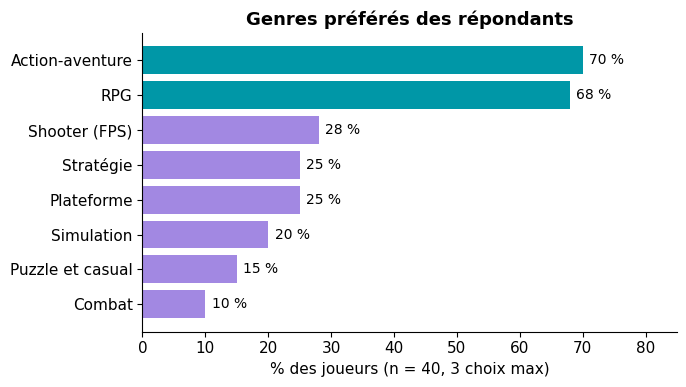

In [22]:
g = multi('genres').head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(g.index, g['%'], color=[CYAN if x in ['Action-aventure', 'RPG'] else LILAS for x in g.index])
for i, val in enumerate(g['%']):
    ax.text(val + 1, i, f'{val:.0f} %', va='center', fontsize=10)
ax.set_xlabel(f'% des joueurs (n = {N}, 3 choix max)'); ax.set_xlim(0, 85)
ax.set_title('Genres préférés des répondants')
save(fig, 'ch_q_genres.png')

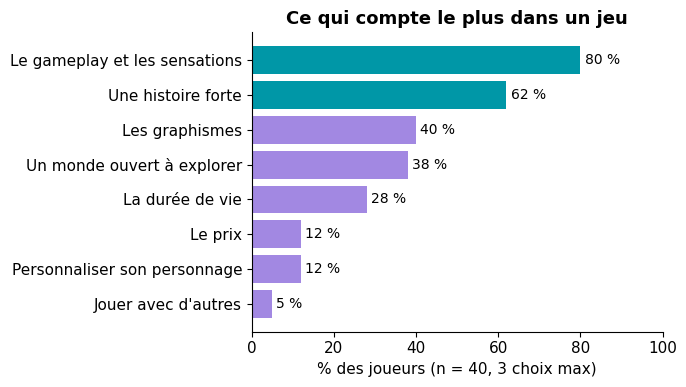

,n,%
criteres,,
Le gameplay et les sensations,32,80.0
Une histoire forte,25,62.0
Les graphismes,16,40.0
Un monde ouvert à explorer,15,38.0
La durée de vie,11,28.0
Le prix,5,12.0
Personnaliser son personnage,5,12.0
Jouer avec d'autres,2,5.0


In [23]:
c = multi('criteres').iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(c.index, c['%'], color=[CYAN if x in ['Le gameplay et les sensations', 'Une histoire forte'] else LILAS for x in c.index])
for i, val in enumerate(c['%']):
    ax.text(val + 1, i, f'{val:.0f} %', va='center', fontsize=10)
ax.set_xlabel(f'% des joueurs (n = {N}, 3 choix max)'); ax.set_xlim(0, 100)
ax.set_title("Ce qui compte le plus dans un jeu")
save(fig, 'ch_q_criteres.png')
c.iloc[::-1]

plateforme_achat
PC                                19
PlayStation 5                     10
Nintendo Switch ou Switch 2        4
Je n'achète pas ce type de jeu     3
Xbox Series                        3
Autre                              1
Name: count, dtype: int64 
 prix
Rien (je joue à des jeux gratuits)     1
Moins de 40 €                          7
40-59 €                               15
60-79 €                               13
80 € ou plus                           4
Name: count, dtype: int64


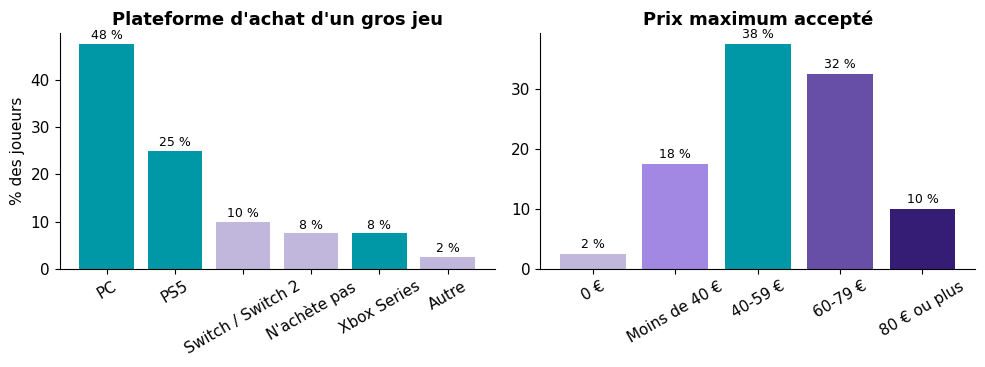

In [24]:
pa = j['plateforme_achat'].value_counts()
ordre_prix = ['Rien (je joue à des jeux gratuits)', 'Moins de 40 €', '40-59 €', '60-79 €', '80 € ou plus']
pr = j['prix'].value_counts().reindex(ordre_prix).fillna(0)
print(pa, '\n', pr)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
lab = {'PC': 'PC', 'PlayStation 5': 'PS5', 'Nintendo Switch ou Switch 2': 'Switch / Switch 2', 'Xbox Series': 'Xbox Series',
       "Je n'achète pas ce type de jeu": "N'achète pas", 'Autre': 'Autre'}
pa2 = pa.rename(index=lab)
axes[0].bar(pa2.index, pa2.values / N * 100, color=[CYAN if x in ['PC', 'PS5', 'Xbox Series'] else PALE for x in pa2.index])
axes[0].set_title("Plateforme d'achat d'un gros jeu"); axes[0].set_ylabel('% des joueurs')
axes[0].tick_params(axis='x', rotation=30)
for i, val in enumerate(pa2.values):
    axes[0].text(i, val / N * 100 + 1, f'{val / N * 100:.0f} %', ha='center', fontsize=9)
pr2 = pr.rename(index={'Rien (je joue à des jeux gratuits)': '0 €'})
axes[1].bar(pr2.index, pr2.values / N * 100, color=[PALE, LILAS, CYAN, VIOLET2, VIOLET])
axes[1].set_title('Prix maximum accepté'); axes[1].tick_params(axis='x', rotation=30)
for i, val in enumerate(pr2.values):
    axes[1].text(i, val / N * 100 + 1, f'{val / N * 100:.0f} %', ha='center', fontsize=9)
save(fig, 'ch_q_plateforme_prix.png')

Intérêt moyen pour le concept : 3.65 / 5 ; note 4 ou 5 : 26 / 40
Solo (1) ↔ multi (5) : {1.0: 12, 2.0: 12, 3.0: 13, 4.0: 2, 5.0: 1}
Licence connue (1) ↔ nouvel univers (5) : {2.0: 8, 3.0: 21, 4.0: 7, 5.0: 4}


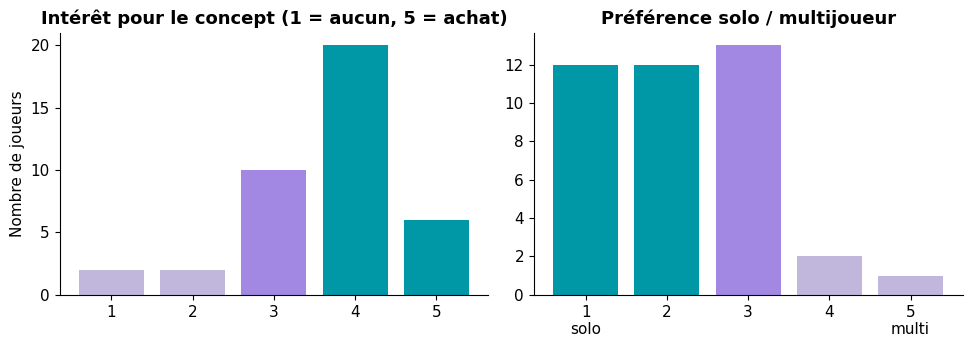

In [25]:
co = j['concept'].value_counts().reindex([1.0, 2.0, 3.0, 4.0, 5.0]).fillna(0)
print(f'Intérêt moyen pour le concept : {j.concept.mean():.2f} / 5 ; note 4 ou 5 : {(j.concept >= 4).sum()} / {N}')
so = j['solo_multi'].value_counts().reindex([1.0, 2.0, 3.0, 4.0, 5.0]).fillna(0)
print('Solo (1) ↔ multi (5) :', so.to_dict())
print('Licence connue (1) ↔ nouvel univers (5) :', j['licence'].value_counts().sort_index().to_dict())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(['1', '2', '3', '4', '5'], co.values, color=[PALE, PALE, LILAS, CYAN, CYAN])
axes[0].set_title('Intérêt pour le concept (1 = aucun, 5 = achat)'); axes[0].set_ylabel('Nombre de joueurs')
axes[1].bar(['1\nsolo', '2', '3', '4', '5\nmulti'], so.values, color=[CYAN, CYAN, LILAS, PALE, PALE])
axes[1].set_title('Préférence solo / multijoueur')
save(fig, 'ch_q_concept_solo.png')

In [26]:
multi('leviers')

,n,%
leviers,,
Recommandation d'amis,22,55.0
Bande-annonce,18,45.0
Avis de joueurs ou de la presse,18,45.0
Prix ou promotion,16,40.0
Streamers et YouTubers,14,35.0
Licence connue,13,32.0
Adaptation en série ou film,1,2.0


### Chiffres regroupés repris dans la présentation

Certains pourcentages de la présentation additionnent plusieurs réponses. Ils sont calculés ici pour être vérifiables.

In [27]:
pa = j['plateforme_achat'].value_counts()
pr = j['prix'].value_counts()
n_pc_ps5_xbox = pa.get('PC', 0) + pa.get('PlayStation 5', 0) + pa.get('Xbox Series', 0)
n_40_plus = pr.get('40-59 €', 0) + pr.get('60-79 €', 0) + pr.get('80 € ou plus', 0)
n_60_plus = pr.get('60-79 €', 0) + pr.get('80 € ou plus', 0)
n_solo = (j['solo_multi'] <= 2).sum(); n_multi = (j['solo_multi'] >= 4).sum()
n_concept45 = (j['concept'] >= 4).sum()
lignes = [('Achèteraient un gros jeu sur PC, PS5 ou Xbox', n_pc_ps5_xbox),
          ('Acceptent 40 € ou plus', n_40_plus), ('Acceptent 60 € ou plus', n_60_plus),
          ('Préfèrent le solo (note 1 ou 2)', n_solo), ('Préfèrent le multijoueur (note 4 ou 5)', n_multi),
          ('Donnent 4 ou 5 au concept', n_concept45)]
pd.DataFrame([(l, n, f'{n} / {N}', round(n / N * 100)) for l, n in lignes], columns=['indicateur', 'n', 'calcul', '%'])

,indicateur,n,calcul,%
0,"Achèteraient un gros jeu sur PC, PS5 ou Xbox",32,32 / 40,80
1,Acceptent 40 € ou plus,32,32 / 40,80
2,Acceptent 60 € ou plus,17,17 / 40,42
3,Préfèrent le solo (note 1 ou 2),24,24 / 40,60
4,Préfèrent le multijoueur (note 4 ou 5),3,3 / 40,8
5,Donnent 4 ou 5 au concept,26,26 / 40,65


### 7.1 Tests de corrélation (Spearman) sur les réponses

➜ **Utilisé dans la présentation : diapositive 18** (« aucune corrélation significative »).

In [28]:
j['age_o'] = j['age'].map({'Moins de 18 ans': 0, '18-24 ans': 1, '25-34 ans': 2, '35-44 ans': 3, '45-54 ans': 4, '55 ans et plus': 5})
j['heures_o'] = j['heures'].map({"Moins d'1 h": 1, '1-5 h': 2, '5-10 h': 3, '10-20 h': 4, 'Plus de 20 h': 5})
j['prix_o'] = j['prix'].map({'Rien (je joue à des jeux gratuits)': 0, 'Moins de 40 €': 1, '40-59 €': 2, '60-79 €': 3, '80 € ou plus': 4})
hyp = [('H2', 'age_o', 'concept', "Les plus jeunes sont plus intéressés par le concept"),
       ('H3', 'heures_o', 'prix_o', "Les gros joueurs acceptent de payer plus cher"),
       ('H4', 'solo_multi', 'concept', "Les joueurs orientés solo aiment davantage le concept"),
       ('H5', 'licence', 'concept', "Les joueurs ouverts aux nouveaux univers aiment davantage le concept")]
rows = []
for h, a, b, txt in hyp:
    s = j[[a, b]].dropna(); r_, p_ = spearmanr(s[a], s[b])
    rows.append([h, txt, len(s), round(r_, 2), round(p_, 3), 'oui' if p_ < 0.05 else 'non'])
tests = pd.DataFrame(rows, columns=['hypothèse', 'énoncé', 'n', 'rho', 'p-value', 'significatif (5 %)'])
tests

,hypothèse,énoncé,n,rho,p-value,significatif (5 %)
0,H2,Les plus jeunes sont plus intéressés par le co...,40,-0.17,0.296,non
1,H3,Les gros joueurs acceptent de payer plus cher,40,0.16,0.334,non
2,H4,Les joueurs orientés solo aiment davantage le ...,40,0.05,0.769,non
3,H5,Les joueurs ouverts aux nouveaux univers aimen...,40,0.07,0.651,non


**Lecture** : aucune des quatre hypothèses n'est significative sur 40 joueurs. On ne peut ni les confirmer ni les infirmer. En revanche, l'absence de lien entre l'intérêt pour le concept et l'âge, la préférence solo ou l'ouverture aux nouveaux univers indique que **l'intérêt pour le concept est assez homogène** dans l'échantillon.

*Point de vigilance* : sur une version intermédiaire (25 joueurs), H3 était significative (ρ = 0,46, p = 0,02) ; elle ne l'est plus avec 31 puis 40 joueurs. Cela illustre l'instabilité des corrélations sur un petit échantillon : il faudrait au moins une centaine de répondants pour conclure.

## 8. Prévision grossière des ventes (3 scénarios)

➜ **Utilisé dans la présentation : diapositive 25.** Type : repères trouvés en ligne (Clair Obscur) + calculs sur le fichier fourni (section 2.3) + multiplication par le prix.

**Principe** : estimation par **jeux comparables**, sans calcul de coût de développement (hors périmètre demandé). Horizon : environ 12 mois après la sortie. Plateformes : PC, PS5, Xbox Series.

| Scénario | Ventes | Repère utilisé | Source |
|---|---|---|---|
| Prudent | 2,7 M | Seuil du top 10 % des jeux d'action 2013-2016 (PS4, Xbox One, PC) | Fichier fourni, section 2.3 |
| Central | 5 M | *Clair Obscur: Expedition 33* (nouvelle licence, multiplateforme) : 5 M annoncés fin octobre 2025, pour une sortie fin avril 2025 ; *Watch Dogs* ≈ 6,3 M et *Shadow of Mordor* ≈ 4,7 M dans le fichier | Sandfall/Kepler (via RPG Site) ; fichier fourni |
| Ambitieux | 8 M | *Clair Obscur: Expedition 33* : 8 M en 12 mois | Sandfall/Kepler (via TweakTown, RPG Site) |

*Black Myth: Wukong* (30 M en moins de 2 ans) n'est pas retenu comme repère : succès exceptionnel, porté pour près de moitié par le marché chinois.

**Prix retenu : 59,99 €.** Justification : 40-59 € est la tranche de prix maximum la plus choisie (38 % des joueurs), et 42 % acceptent même 60 € et plus : 59,99 € reste dans le budget annoncé par une large majorité ; Newzoo note que les jeux à prix intermédiaire ont particulièrement bien fonctionné en 2025.

In [29]:
prix = 59.99
scen = pd.DataFrame({'scenario': ['Prudent', 'Central', 'Ambitieux'], 'ventes_M': [2.7, 5.0, 8.0]})
scen['CA_consommateur_M€'] = (scen['ventes_M'] * prix).round(0)
base_console = 95.3 + 34.17
scen['%_parc_PS5_XboxSeries'] = (scen['ventes_M'] / base_console * 100).round(1)
part_ps5 = 95.3 / base_console * 100
print(f'Parc PS5 + Xbox Series : {base_console:.1f} M. Une exclusivité PS5 ne touche que {part_ps5:.0f} % de ce parc, '
      f'soit {100 - part_ps5:.0f} % de public console en moins (environ un quart).')
print('Rappel : CA calculé au prix public (TTC), avant déduction de la TVA, des commissions des plateformes et des remises. Indicatif.')
scen

Parc PS5 + Xbox Series : 129.5 M. Une exclusivité PS5 ne touche que 74 % de ce parc, soit 26 % de public console en moins (environ un quart).
Rappel : CA calculé au prix public (TTC), avant déduction de la TVA, des commissions des plateformes et des remises. Indicatif.


,scenario,ventes_M,CA_consommateur_M€,%_parc_PS5_XboxSeries
0,Prudent,2.7,162.0,2.1
1,Central,5.0,300.0,3.9
2,Ambitieux,8.0,480.0,6.2


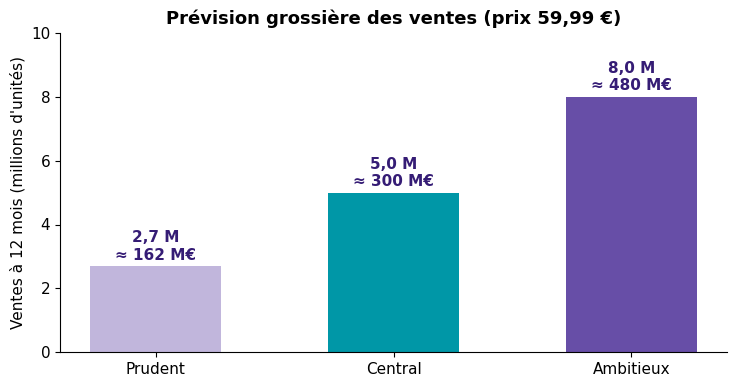

In [30]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(scen['scenario'], scen['ventes_M'], color=[PALE, CYAN, VIOLET2], width=0.55)
for i, (v_, ca) in enumerate(zip(scen['ventes_M'], scen['CA_consommateur_M€'])):
    ax.text(i, v_ + 0.2, f'{v_:.1f} M\n≈ {ca:.0f} M€'.replace('.', ','), ha='center', fontsize=11, fontweight='bold', color=VIOLET)
ax.set_ylabel("Ventes à 12 mois (millions d'unités)"); ax.set_ylim(0, 10)
ax.set_title('Prévision grossière des ventes (prix 59,99 €)')
save(fig, 'ch_prevision.png')

**Lecture** : le scénario central (5 M d'exemplaires, ≈ 300 M€ de chiffre d'affaires au prix public) suppose un jeu très bien reçu. D'après la section 4, la note critique est le facteur le plus lié aux ventes : viser une note Metacritic d'au moins 85 conditionne le passage du scénario prudent au scénario central.

## 9. Sources

**Données fournies**
- `VideoGame_Sales_1980-2016.xlsb` : ventes de jeux de plus de 100 000 exemplaires
- `All_publish_VideoGame_2022.xlsb` : tous les jeux avec notes des joueurs
- `Vente_de_console_2022.xlsx` : ventes de consoles

**Données collectées**
- Questionnaire Google Forms « Tes habitudes de jeu vidéo » (43 réponses, 30/10 au 09/11/2026)

**Sources externes**
- Newzoo, Global Games Market Report 2025 (chiffres relayés par Pocketgamer.biz, GameDev.net / GamesIndustry.biz, GameDevReports) : marché 2025, segments, prévision 2028
- SELL, *L'Essentiel du jeu vidéo – Bilan du marché français 2025*, avril 2026 : https://www.sell.fr/sites/default/files/essentiel-jeu-video/ejv_avril_2026_final_.pdf
- SELL / Médiamétrie, *Les Français et le jeu vidéo 2025*, septembre 2025
- Sony, résultats T1 exercice 2026 (via Thurrott) et exercice 2025 (via Gematsu) : parc PS5, part du dématérialisé
- Nintendo, résultats T1 exercice 2027 (via Nintendo Life, FullCleared) : Switch 2 et Switch
- VGChartz, estimation Xbox Series (déc. 2025)
- SteamDB (via Kotaku, KitGuru, octobre 2026) : record d'utilisateurs Steam connectés simultanément
- Sandfall Interactive / Kepler Interactive (via RPG Site, TweakTown, Smilegate newsroom) : ventes de *Clair Obscur: Expedition 33*
- Game Science / Communist Youth League of China (via KitGuru, Gagadget) : ventes de *Black Myth: Wukong*
- GDC, *State of the Game Industry 2026* : IA générative, licenciements
- Commission européenne, *Digital Fairness Act* (consultation 2025, proposition attendue fin 2026)
- CNC / Assemblée nationale : crédit d'impôt jeu vidéo (30 % des dépenses éligibles, plafond 6 M€)
- ADEME / Arcep (juin 2024) : empreinte environnementale du jeu vidéo
- Presse spécialisée (Justgeek, Tom's Guide, Tech-Insider) : hausses de prix des consoles 2026